In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import spearmanr, kendalltau

import shap
from lime.lime_tabular import LimeTabularExplainer

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# -----------------------------
# 1. Load and preprocess data
# -----------------------------
data_path = "../../data/diabetes/diabetes.csv"
df = pd.read_csv(data_path)

zero_invalid = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df_imp = df.copy()
df_imp[zero_invalid] = df_imp[zero_invalid].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
df_imp[zero_invalid] = imputer.fit_transform(df_imp[zero_invalid])

full_cols = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]

cols_5 = ["Glucose", "BMI", "Age", "Insulin", "SkinThickness"]

X = df_imp[full_cols]
y = df_imp["Outcome"]

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X,
    y,
    test_size=230,
    stratify=y,
    random_state=42
)

X_train_5 = X_train_full[cols_5].copy()
X_test_5 = X_test_full[cols_5].copy()


In [3]:
# -----------------------------
# 2. Train final XAI target model
# -----------------------------
final_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)
final_model.fit(X_train_5, y_train)

y_pred = final_model.predict(X_test_5)
y_prob = final_model.predict_proba(X_test_5)[:, 1]

print("Final XAI model: Random Forest on 5-factor dataset")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1       :", round(f1_score(y_test, y_pred), 4))
print("AUC      :", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

# Output directory
out_dir = "xai_outputs_diabetes"
os.makedirs(out_dir, exist_ok=True)


Final XAI model: Random Forest on 5-factor dataset
Accuracy : 0.7522
Precision: 0.6575
Recall   : 0.6
F1       : 0.6275
AUC      : 0.8158

Confusion matrix:
[[125  25]
 [ 32  48]]



Permutation importance
         Feature  PermutationMean  PermutationStd
0        Glucose           0.0767          0.0224
1            BMI           0.0412          0.0165
2            Age           0.0283          0.0112
3        Insulin           0.0190          0.0152
4  SkinThickness           0.0113          0.0100


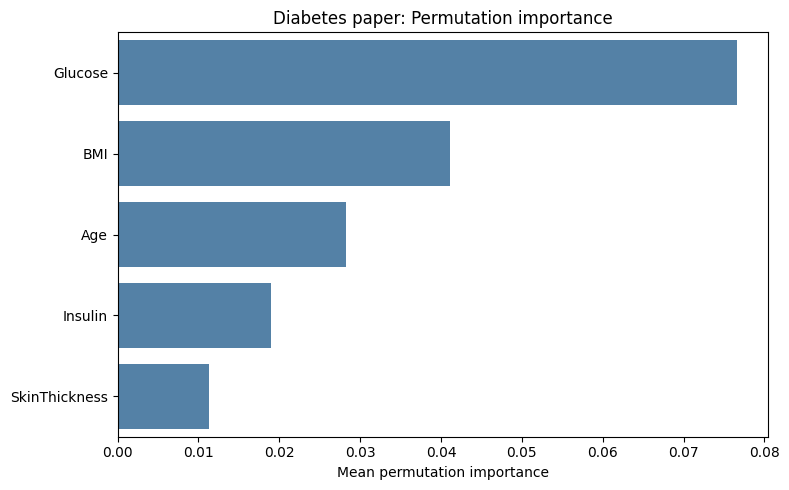

In [4]:
# -----------------------------
# 3. Global XAI: Permutation importance
# -----------------------------
perm = permutation_importance(
    final_model,
    X_test_5,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="accuracy"
)

perm_df = pd.DataFrame({
    "Feature": X_test_5.columns,
    "PermutationMean": perm.importances_mean,
    "PermutationStd": perm.importances_std
}).sort_values("PermutationMean", ascending=False)

print("\nPermutation importance")
print(perm_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=perm_df, x="PermutationMean", y="Feature", color="steelblue")
plt.xlabel("Mean permutation importance")
plt.ylabel("")
plt.title("Diabetes paper: Permutation importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_permutation_importance.png"), dpi=300)
plt.show()


In [5]:
print(type(shap_values))
print(np.array(shap_values).shape)
print(np.array(shap_plot_values).shape if 'shap_plot_values' in locals() else "not set")


NameError: name 'shap_values' is not defined

Final SHAP matrix shape: (230, 5)


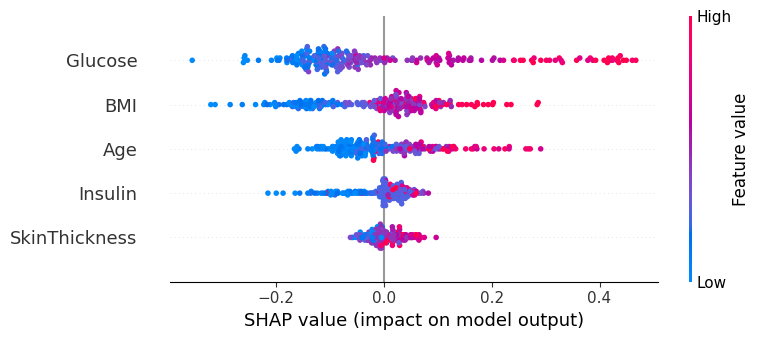

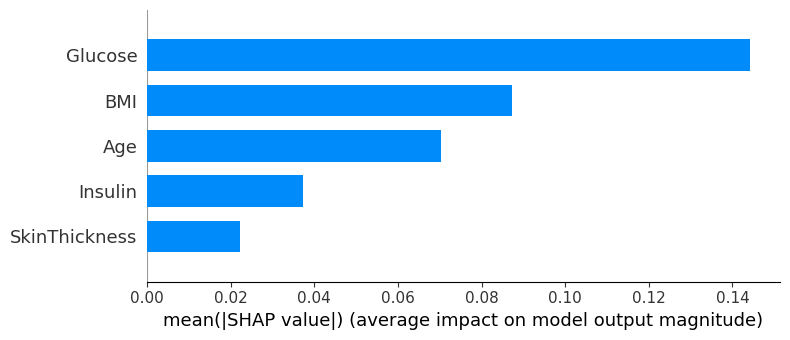


SHAP importance
         Feature  MeanAbsSHAP
0        Glucose       0.1442
1            BMI       0.0872
2            Age       0.0702
3        Insulin       0.0373
4  SkinThickness       0.0223


In [ ]:
# -----------------------------
# 4. Global XAI: SHAP importance
# -----------------------------
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_5)

if isinstance(shap_values, list):
    shap_plot_values = shap_values[1]
    expected_value = explainer.expected_value[1]
else:
    shap_values = np.array(shap_values)

    if shap_values.ndim == 3:
        shap_plot_values = shap_values[:, :, 1]
        expected_value = (
            explainer.expected_value[1]
            if np.ndim(explainer.expected_value) > 0
            else explainer.expected_value
        )
    else:
        shap_plot_values = shap_values
        expected_value = explainer.expected_value

print("Final SHAP matrix shape:", shap_plot_values.shape)

# SHAP summary beeswarm
shap.summary_plot(shap_plot_values, X_test_5, show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_shap_summary.png"), dpi=300, bbox_inches="tight")
plt.show()

# SHAP summary bar
shap.summary_plot(shap_plot_values, X_test_5, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_shap_bar.png"), dpi=300, bbox_inches="tight")
plt.show()

shap_imp = pd.DataFrame({
    "Feature": X_test_5.columns,
    "MeanAbsSHAP": np.abs(shap_plot_values).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print("\nSHAP importance")
print(shap_imp.round(4))


In [ ]:
print("Final SHAP matrix shape:", shap_plot_values.shape)


Final SHAP matrix shape: (230, 5)


In [ ]:
# -----------------------------
# 5. Compare replication ranking with paper ranking
# -----------------------------
paper_rank = pd.DataFrame({
    "Feature": ["Glucose", "BMI", "Age", "Insulin", "SkinThickness"],
    "PaperRank": [1, 2, 3, 4, 5]
})

xai_rank = shap_imp.reset_index(drop=True).copy()
xai_rank["ReplicationRank"] = np.arange(1, len(xai_rank) + 1)

rank_compare = paper_rank.merge(
    xai_rank[["Feature", "ReplicationRank", "MeanAbsSHAP"]],
    on="Feature",
    how="left"
)

rho, rho_p = spearmanr(rank_compare["PaperRank"], rank_compare["ReplicationRank"])
tau, tau_p = kendalltau(rank_compare["PaperRank"], rank_compare["ReplicationRank"])

print("\nPaper vs replication rank comparison")
print(rank_compare.round(4))
print(f"\nSpearman rank correlation: {rho:.4f} (p={rho_p:.4f})")
print(f"Kendall tau: {tau:.4f} (p={tau_p:.4f})")

# Compare SHAP ranking with permutation importance ranking
perm_rank = perm_df[["Feature"]].reset_index(drop=True).copy()
perm_rank["PermutationRank"] = np.arange(1, len(perm_rank) + 1)

agreement_df = rank_compare.merge(perm_rank, on="Feature", how="left")

rho_shap_perm, p_shap_perm = spearmanr(
    agreement_df["ReplicationRank"],
    agreement_df["PermutationRank"]
)

print("\nSHAP vs permutation ranking comparison")
print(agreement_df.round(4))
print(f"Spearman correlation between SHAP rank and permutation rank: {rho_shap_perm:.4f} (p={p_shap_perm:.4f})")

# Optional rank difference
rank_compare["RankDifference"] = (
    rank_compare["PaperRank"] - rank_compare["ReplicationRank"]
).abs()

if rank_compare["RankDifference"].sum() == 0:
    print("\nPaper and replication rankings are identical; rank-difference plot omitted.")
else:
    plt.figure(figsize=(7, 4))
    sns.barplot(
        data=rank_compare.sort_values("PaperRank"),
        x="Feature",
        y="RankDifference",
        color="darkorange"
    )
    plt.title("Absolute rank difference: paper vs replication")
    plt.ylabel("|Paper rank - Replication rank|")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "diabetes_rank_difference.png"), dpi=300)
    plt.show()



Paper vs replication rank comparison
         Feature  PaperRank  ReplicationRank  MeanAbsSHAP
0        Glucose          1                1       0.1442
1            BMI          2                2       0.0872
2            Age          3                3       0.0702
3        Insulin          4                4       0.0373
4  SkinThickness          5                5       0.0223

Spearman rank correlation: 1.0000 (p=0.0000)
Kendall tau: 1.0000 (p=0.0167)

SHAP vs permutation ranking comparison
         Feature  PaperRank  ReplicationRank  MeanAbsSHAP  PermutationRank
0        Glucose          1                1       0.1442                1
1            BMI          2                2       0.0872                2
2            Age          3                3       0.0702                3
3        Insulin          4                4       0.0373                4
4  SkinThickness          5                5       0.0223                5
Spearman correlation between SHAP rank and perm


Top 3 SHAP features: ['Glucose', 'BMI', 'Age']


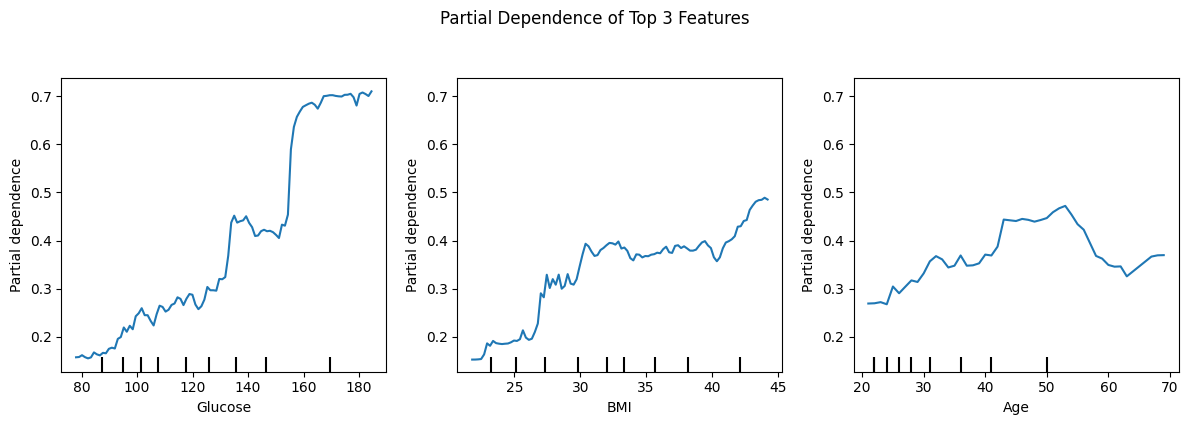

In [ ]:
# -----------------------------
# 6. Functional XAI: Partial dependence plots
# -----------------------------
top_features = shap_imp["Feature"].head(3).tolist()
print("\nTop 3 SHAP features:", top_features)

fig, ax = plt.subplots(1, len(top_features), figsize=(12, 4))

PartialDependenceDisplay.from_estimator(
    final_model,
    X_test_5,
    features=top_features,
    ax=ax
)

plt.suptitle("Partial Dependence of Top 3 Features", y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_pdp_top3.png"), dpi=300, bbox_inches="tight")
plt.show()



Representative cases
     Glucose   BMI  Age  Insulin  SkinThickness  y_true  y_pred  y_prob  \
300    167.0  32.3   30    125.0           29.0       1       1  0.9767   
589     73.0  21.1   25    125.0           29.0       0       0  0.0000   
335    165.0  47.9   26    255.0           43.0       0       1  0.9200   
276    106.0  26.5   29    125.0           24.0       1       0  0.0200   
727    141.0  32.4   22    125.0           26.0       0       0  0.5000   

     dist_to_05    CaseType  
300      0.4767          TP  
589      0.5000          TN  
335      0.4200          FP  
276      0.4800          FN  
727      0.0000  Borderline  

Representative indices: [300, 589, 335, 276, 727]

SHAP local explanation for case 300
CaseType          TP
y_true             1
y_pred             1
y_prob      0.976667
Name: 300, dtype: object


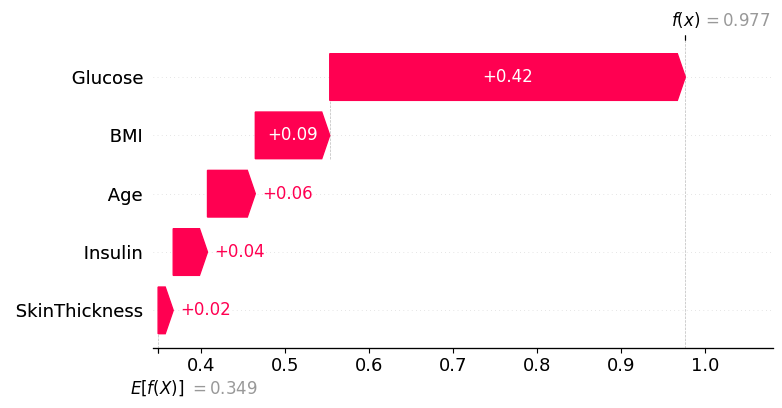

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 589
CaseType     TN
y_true        0
y_pred        0
y_prob      0.0
Name: 589, dtype: object


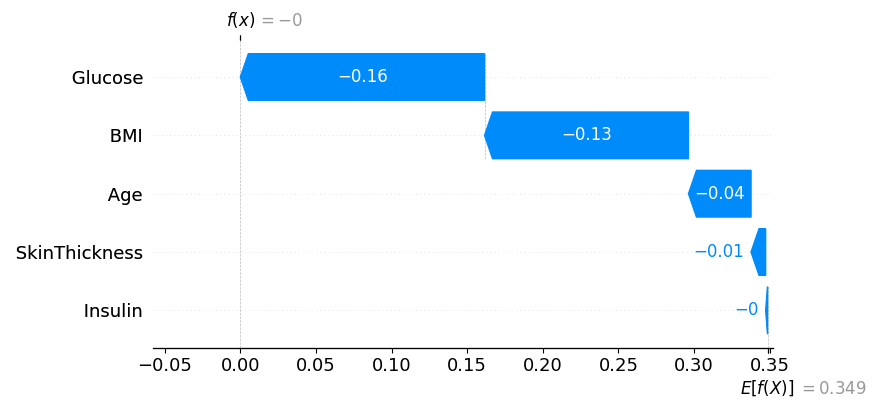

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 335
CaseType      FP
y_true         0
y_pred         1
y_prob      0.92
Name: 335, dtype: object


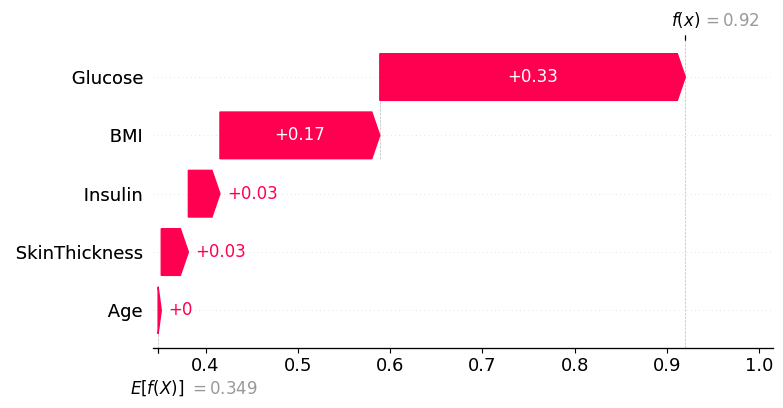

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 276
CaseType      FN
y_true         1
y_pred         0
y_prob      0.02
Name: 276, dtype: object


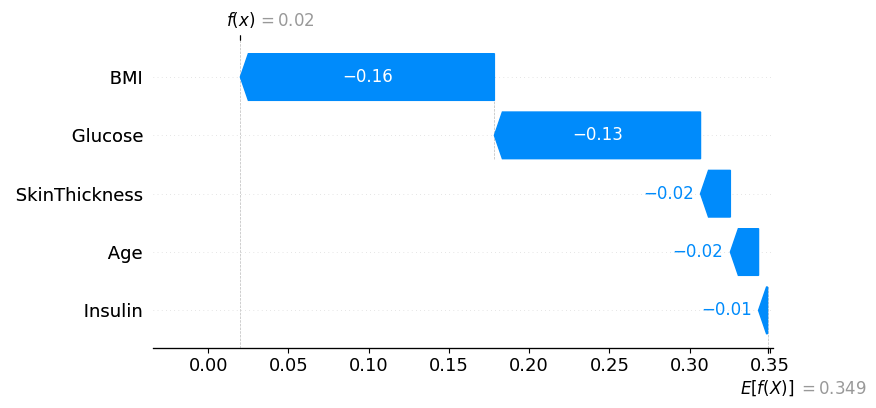

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 727
CaseType    Borderline
y_true               0
y_pred               0
y_prob             0.5
Name: 727, dtype: object


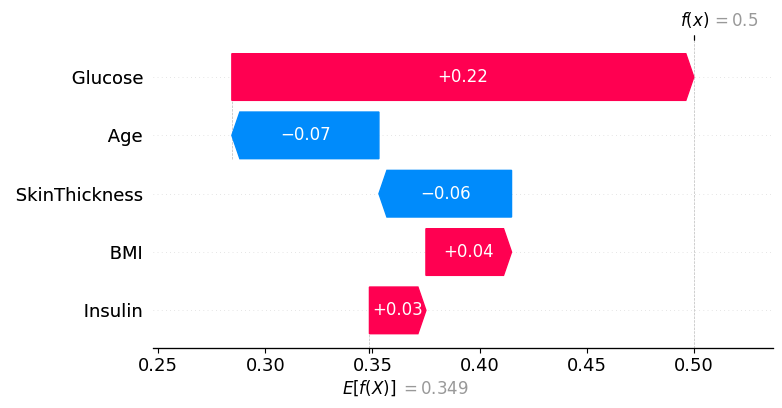

<Figure size 640x480 with 0 Axes>

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 300
CaseType          TP
y_true             1
y_pred             1
y_prob      0.976667
Name: 300, dtype: object
[('Glucose > 141.00', 0.3703328603764846), ('122.00 < Insulin <= 125.00', 0.04456919440994243), ('24.00 < Age <= 30.00', -0.033916381988405776), ('25.25 < SkinThickness <= 29.00', -0.024273821289422064), ('27.82 < BMI <= 32.40', 0.019698393632260332)]


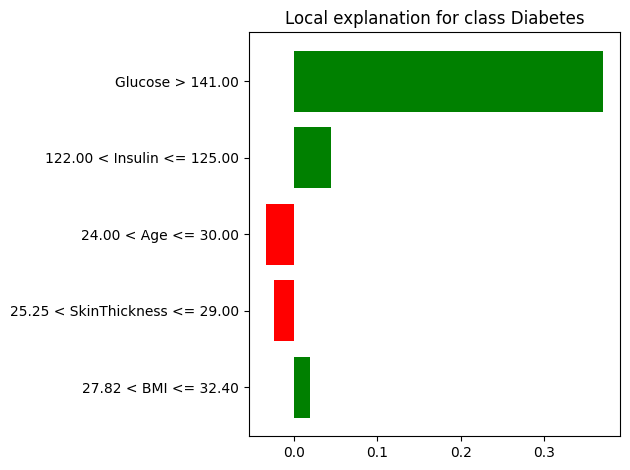

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 589
CaseType     TN
y_true        0
y_pred        0
y_prob      0.0
Name: 589, dtype: object
[('Glucose <= 99.25', -0.2021970251474084), ('BMI <= 27.82', -0.1946185861344262), ('122.00 < Insulin <= 125.00', 0.041688374107693216), ('24.00 < Age <= 30.00', -0.030247210381549903), ('25.25 < SkinThickness <= 29.00', -0.02888481714594546)]


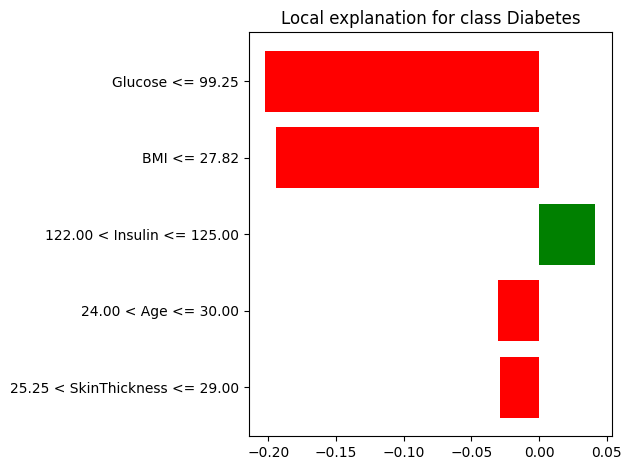

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 335
CaseType      FP
y_true         0
y_pred         1
y_prob      0.92
Name: 335, dtype: object
[('Glucose > 141.00', 0.3617895120526232), ('BMI > 36.38', 0.1404378506556288), ('Insulin > 130.00', 0.07141811919316188), ('SkinThickness > 32.00', 0.05630344289117847), ('24.00 < Age <= 30.00', -0.023682834051940816)]


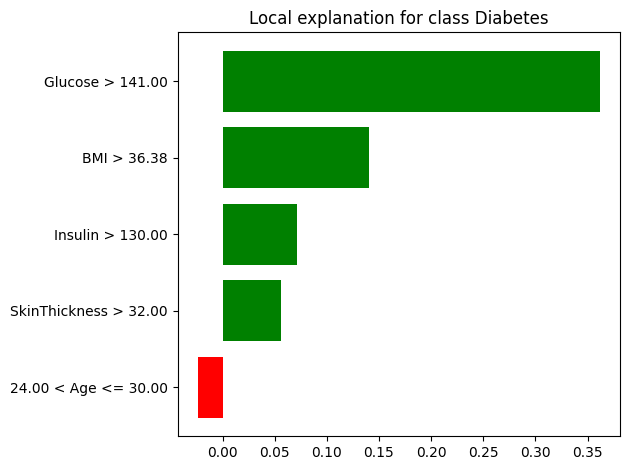

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 276
CaseType      FN
y_true         1
y_pred         0
y_prob      0.02
Name: 276, dtype: object
[('BMI <= 27.82', -0.20227742770681756), ('99.25 < Glucose <= 117.00', -0.11293539266593637), ('24.00 < Age <= 30.00', -0.04917958710273561), ('122.00 < Insulin <= 125.00', 0.04188074267689254), ('SkinThickness <= 25.25', -0.0039029315837326673)]


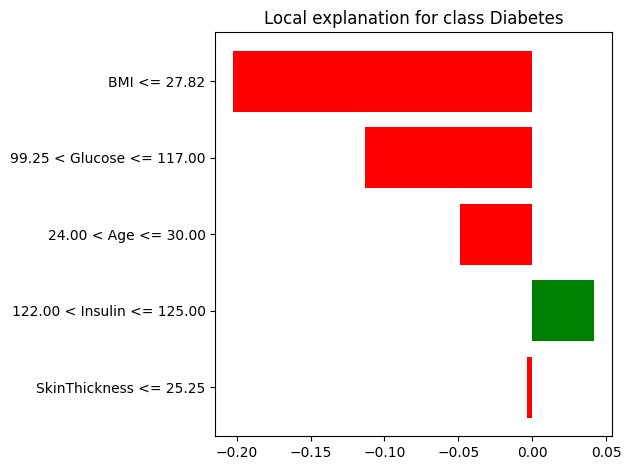

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 727
CaseType    Borderline
y_true               0
y_pred               0
y_prob             0.5
Name: 727, dtype: object
[('Age <= 24.00', -0.13172410287780412), ('122.00 < Insulin <= 125.00', 0.037309951856313105), ('117.00 < Glucose <= 141.00', -0.029210740245170053), ('25.25 < SkinThickness <= 29.00', -0.026389687670252716), ('27.82 < BMI <= 32.40', 0.022015095335923093)]


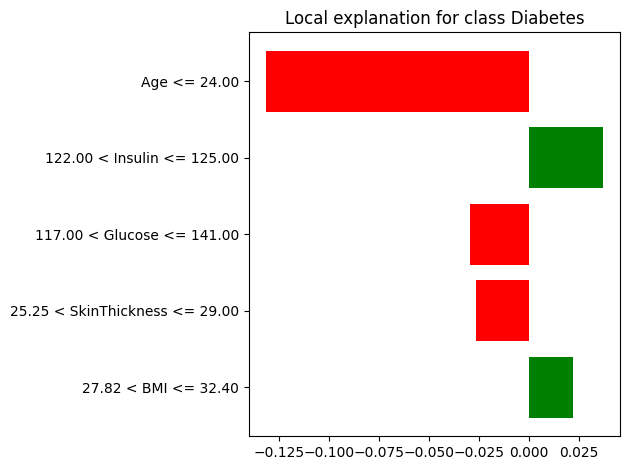

In [ ]:
# -----------------------------
# 7. Local XAI: representative cases
# -----------------------------
case_df = X_test_5.copy()
case_df["y_true"] = y_test.values
case_df["y_pred"] = y_pred
case_df["y_prob"] = y_prob
case_df["dist_to_05"] = np.abs(case_df["y_prob"] - 0.5)

tp = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

tn = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

fp = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

fn = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

borderline = case_df.sort_values("dist_to_05").head(1).copy()

tp["CaseType"] = "TP"
tn["CaseType"] = "TN"
fp["CaseType"] = "FP"
fn["CaseType"] = "FN"
borderline["CaseType"] = "Borderline"

rep_cases = pd.concat([tp, tn, fp, fn, borderline]).drop_duplicates()

print("\nRepresentative cases")
print(rep_cases.round(4))

rep_indices = rep_cases.index.tolist()
print("\nRepresentative indices:", rep_indices)

rep_cases.to_csv(
    os.path.join(out_dir, "diabetes_xai_representative_cases.csv"),
    index=True
)

# SHAP local explanations
for idx in rep_indices:
    row = X_test_5.loc[[idx]]

    shap_single = explainer.shap_values(row)

    if isinstance(shap_single, list):
        shap_single_plot = shap_single[1]
        local_expected = explainer.expected_value[1]
    else:
        shap_single = np.array(shap_single)

        if shap_single.ndim == 3:
            shap_single_plot = shap_single[:, :, 1]
            local_expected = (
                explainer.expected_value[1]
                if np.ndim(explainer.expected_value) > 0
                else explainer.expected_value
            )
        else:
            shap_single_plot = shap_single
            local_expected = explainer.expected_value

    print(f"\nSHAP local explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])

    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        local_expected,
        shap_single_plot[0],
        feature_names=row.columns.tolist(),
        features=row.iloc[0].values
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"diabetes_shap_waterfall_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# LIME local explanations
lime_explainer = LimeTabularExplainer(
    training_data=X_train_5.values,
    feature_names=X_train_5.columns.tolist(),
    class_names=["No diabetes", "Diabetes"],
    mode="classification"
)

lime_rows = []

for idx in rep_indices:
    exp = lime_explainer.explain_instance(
        X_test_5.loc[idx].values,
        final_model.predict_proba,
        num_features=5
    )

    print(f"\nLIME explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])
    print(exp.as_list())

    for feat, weight in exp.as_list():
        lime_rows.append({
            "CaseIndex": idx,
            "CaseType": rep_cases.loc[idx, "CaseType"],
            "Rule": feat,
            "Weight": weight
        })

    fig = exp.as_pyplot_figure()
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"diabetes_lime_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

lime_df = pd.DataFrame(lime_rows)



Stability summary
               MeanImportance  StdImportance  MeanRank  StdRank
Feature                                                        
Glucose                0.0750         0.0126       1.0   0.0000
BMI                    0.0204         0.0118       2.2   0.4472
Age                    0.0112         0.0135       3.0   0.7071
Insulin                0.0005         0.0021       4.0   0.7071
SkinThickness         -0.0078         0.0102       4.8   0.4472


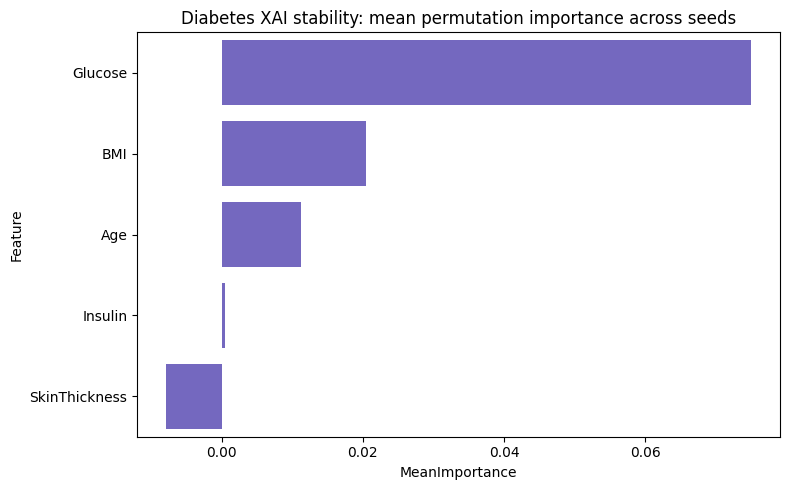


Top-k overlap across seeds
   Seed1  Seed2  TopK_Jaccard
0      1      2           1.0
1      1      3           1.0
2      1      4           0.5
3      1      5           1.0
4      2      3           1.0
5      2      4           0.5
6      2      5           1.0
7      3      4           0.5
8      3      5           1.0
9      4      5           0.5
Mean top-k overlap: 0.8


In [ ]:
# -----------------------------
# 8. Stability analysis across random seeds
# -----------------------------
seeds = [1, 2, 3, 4, 5]
stability_rows = []

for seed in seeds:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        df_imp[cols_5],
        df_imp["Outcome"],
        test_size=230,
        stratify=df_imp["Outcome"],
        random_state=seed
    )

    model_s = RandomForestClassifier(
        n_estimators=300,
        random_state=seed
    )
    model_s.fit(X_train_s, y_train_s)

    perm_s = permutation_importance(
        model_s,
        X_test_s,
        y_test_s,
        n_repeats=10,
        random_state=seed,
        scoring="accuracy"
    )

    temp = pd.DataFrame({
        "Feature": X_test_s.columns,
        "Importance": perm_s.importances_mean,
        "Seed": seed
    })
    stability_rows.append(temp)

stability_df = pd.concat(stability_rows, ignore_index=True)

stability_df["Rank"] = stability_df.groupby("Seed")["Importance"].rank(
    ascending=False,
    method="min"
)

stability_summary = stability_df.groupby("Feature").agg(
    MeanImportance=("Importance", "mean"),
    StdImportance=("Importance", "std"),
    MeanRank=("Rank", "mean"),
    StdRank=("Rank", "std")
).sort_values("MeanRank")

print("\nStability summary")
print(stability_summary.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=stability_summary.reset_index(),
    x="MeanImportance",
    y="Feature",
    color="slateblue"
)
plt.title("Diabetes XAI stability: mean permutation importance across seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_stability_mean_importance.png"), dpi=300)
plt.show()

top_k = 3

top_features_by_seed = (
    stability_df.sort_values(["Seed", "Importance"], ascending=[True, False])
    .groupby("Seed")
    .head(top_k)
    .groupby("Seed")["Feature"]
    .apply(list)
)

overlaps = []
for s1, s2 in combinations(top_features_by_seed.index, 2):
    set1 = set(top_features_by_seed[s1])
    set2 = set(top_features_by_seed[s2])
    jaccard = len(set1 & set2) / len(set1 | set2)
    overlaps.append({
        "Seed1": s1,
        "Seed2": s2,
        "TopK_Jaccard": jaccard
    })

overlap_df = pd.DataFrame(overlaps)
print("\nTop-k overlap across seeds")
print(overlap_df.round(4))
print("Mean top-k overlap:", round(overlap_df["TopK_Jaccard"].mean(), 4))




Feature rank by seed
Seed             1    2    3    4    5
Feature                               
Age            3.0  3.0  3.0  4.0  2.0
BMI            2.0  2.0  2.0  2.0  3.0
Glucose        1.0  1.0  1.0  1.0  1.0
Insulin        4.0  4.0  5.0  3.0  4.0
SkinThickness  5.0  5.0  4.0  5.0  5.0


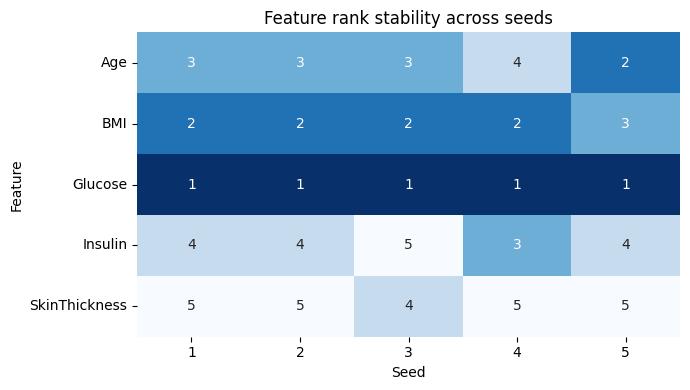

In [ ]:
rank_pivot = stability_df.pivot(index="Feature", columns="Seed", values="Rank")
print("\nFeature rank by seed")
print(rank_pivot)

plt.figure(figsize=(7, 4))
sns.heatmap(rank_pivot, annot=True, cmap="Blues_r", cbar=False)
plt.title("Feature rank stability across seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "diabetes_rank_stability_heatmap.png"), dpi=300)
plt.show()

In [ ]:
# -----------------------------
# 9. Export tables
# -----------------------------
perm_df.to_csv(os.path.join(out_dir, "diabetes_xai_permutation_importance.csv"), index=False)
shap_imp.to_csv(os.path.join(out_dir, "diabetes_xai_shap_importance.csv"), index=False)
rank_compare.to_csv(os.path.join(out_dir, "diabetes_xai_paper_vs_replication_rank.csv"), index=False)
stability_df.to_csv(os.path.join(out_dir, "diabetes_xai_stability_raw.csv"), index=False)
stability_summary.to_csv(os.path.join(out_dir, "diabetes_xai_stability_summary.csv"))
overlap_df.to_csv(os.path.join(out_dir, "diabetes_xai_topk_overlap.csv"), index=False)
rep_cases.to_csv(os.path.join(out_dir, "diabetes_xai_representative_cases.csv"))
lime_df.to_csv(os.path.join(out_dir, "diabetes_xai_lime_cases.csv"), index=False)

print(f"\nAll XAI outputs saved in: {out_dir}")



All XAI outputs saved in: xai_outputs_diabetes


In [ ]:
stability_export = stability_summary.reset_index()[["Feature", "MeanImportance", "MeanRank", "StdRank"]]

final_xai_summary = rank_compare.merge(
    stability_export,
    on="Feature",
    how="left"
).sort_values("PaperRank")

print(final_xai_summary.round(4))

final_xai_summary.to_csv(
    os.path.join(out_dir, "diabetes_xai_final_summary.csv"),
    index=False
)

         Feature  PaperRank  ReplicationRank  MeanAbsSHAP  RankDifference  \
0        Glucose          1                1       0.1442               0   
1            BMI          2                2       0.0872               0   
2            Age          3                3       0.0702               0   
3        Insulin          4                4       0.0373               0   
4  SkinThickness          5                5       0.0223               0   

   MeanImportance  MeanRank  StdRank  
0          0.0750       1.0   0.0000  
1          0.0204       2.2   0.4472  
2          0.0112       3.0   0.7071  
3          0.0005       4.0   0.7071  
4         -0.0078       4.8   0.4472  


preparing for xai data agnostic pipeline

In [ ]:
xai_context = {
    "model": final_model,
    "X_train": X_train_enc,
    "X_test": X_test_enc,
    "y_train": y_train,
    "y_test": y_test,
    "feature_names": X_train_enc.columns.tolist(),
    "model_type": "random_forest"
}

In [6]:
def inspect_model(model):

    print("=" * 50)

    print("TYPE")
    print(type(model))

    print("\nCLASS")
    print(model.__class__.__name__)

    print("\nMODULE")
    print(model.__class__.__module__)

    print("\nCAPABILITIES")

    for attr in [
        "predict",
        "predict_proba",
        "coef_",
        "params",
        "feature_importances_"
    ]:

        print(
            f"{attr}:",
            hasattr(model, attr)
        )

    print("=" * 50)

In [7]:
inspect_model(final_model)

TYPE
<class 'sklearn.ensemble._forest.RandomForestClassifier'>

CLASS
RandomForestClassifier

MODULE
sklearn.ensemble._forest

CAPABILITIES
predict: True
predict_proba: True
coef_: False
params: False
feature_importances_: True
